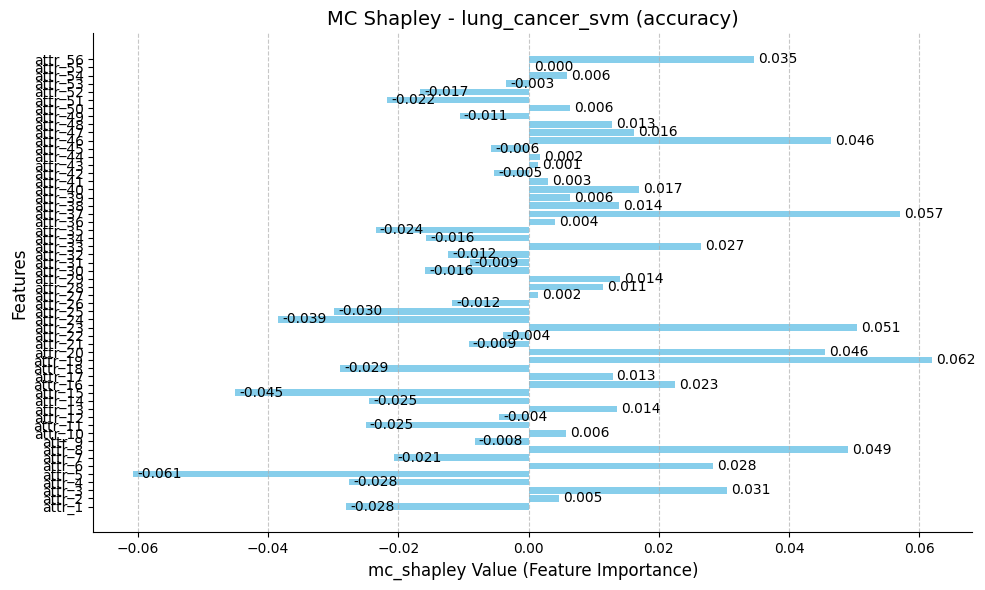

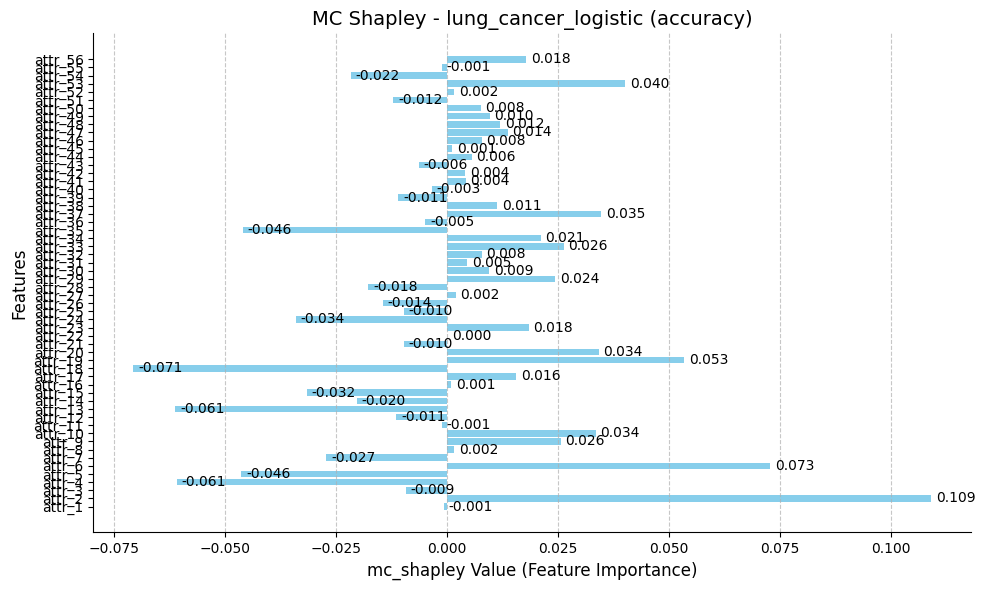

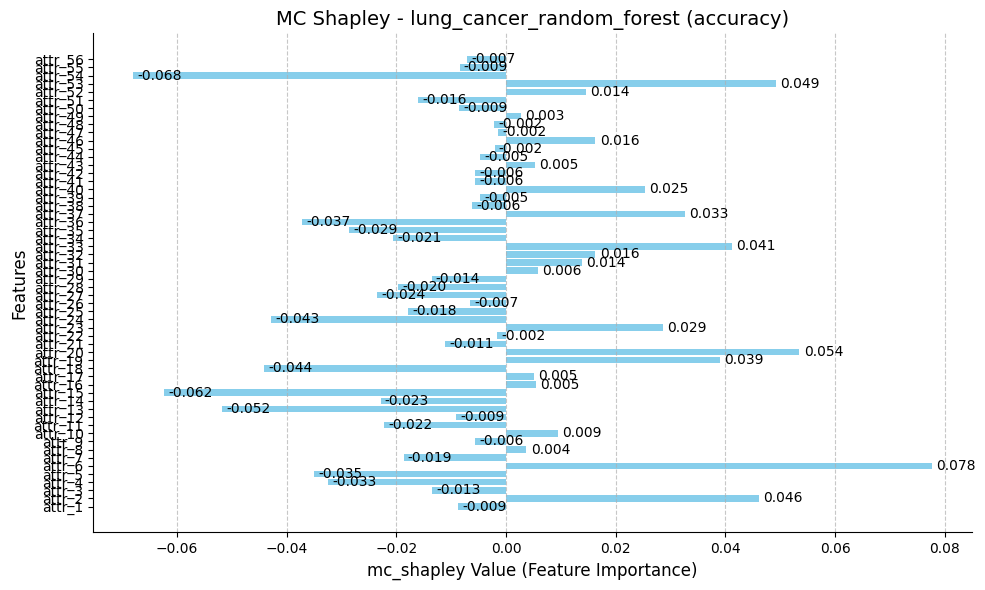

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config

DATASETS = ["lung_cancer"]   #UCI datasets
MODEL_NAMES = ["svm", "logistic", "random_forest"]          # adjust names to match get_model()
SCORING = "accuracy"
N_MC_ITERATIONS = 1000
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Dataset loaders for UCI Lung Cancer and MI Complications

def load_lung_cancer():
    """
    UCI Lung Cancer dataset:
    - File: lung-cancer.data
    - First column: class label (1,2,3)
    - Rest: features (some '?')
    """
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # target
    y = df.iloc[:, 0].astype(int).values

    # features
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    """
    UCI Myocardial Infarction Complications dataset:
    - File: MI.data
    - We'll treat LET_IS (col 123) as binary death outcome (dead vs alive).
    - Features: columns 1..111
    """
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # features: columns 1..111
    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    # LET_IS at column 123: 0 = alive, 1..7 = different death categories
    let_is = df.iloc[:, 123].astype(int).values

    if binary_let_is:
        y = (let_is != 0).astype(int)
    else:
        y = let_is  # multi-class (0..7)

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")


class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority-class baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")


# Main: do "all the things" for each dataset + model

def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "="*70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("="*70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            all_features_set = set(range(n_features))
            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            # 1. MC Shapley feature attributions (NO exact)
            logger.info("Computing Monte Carlo Shapley values...")
            shapley_result = montecarlo_shapley_value(
                utility,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals = shapley_result.values

            # Save per-feature values
            df_vals = pd.DataFrame({
                "method": "mc_shapley",
                "feature": feature_names,
                "value": shapley_vals
            })
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_mc_shapley.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved MC Shapley valuations to: {vals_csv_path}")

            # Optional: bar plot
            try:
                plot_single_valuation(
                    shapley_vals,
                    feature_names,
                    method_name="mc_shapley",
                    title=f"MC Shapley - {dataset_name}_{model_name} ({SCORING})",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_mc_shapley.png"
                )
            except Exception as e:
                logger.warning(f"  Could not plot MC Shapley for {dataset_name}, {model_name}: {e}")

            results = {"mc_shapley": shapley_vals}

            # 2. Global sensitivity (leave-one-out impact)
            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

            global_impacts = []
            for i in range(n_features):
                features_except_i = list(all_features_set - {i})
                v_N_minus_i = utility(features_except_i)
                impact = v_N - v_N_minus_i
                global_impacts.append(impact)
                logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

            global_impact_vector = np.array(global_impacts)

            sensitivity_results = []
            for method_name, attribution_values in results.items():
                if attribution_values is None:
                    logger.warning(f"  Skipping {method_name} (None values)")
                    continue

                corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)
                corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

                cos_sim = np.dot(attribution_values, global_impact_vector) / (
                    (np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector)) + 1e-10
                )

                sensitivity_results.append({
                    "method": method_name,
                    "sensitivity_spearman": corr_spearman,
                    "p_value_spearman": p_spearman,
                    "sensitivity_pearson": corr_pearson,
                    "p_value_pearson": p_pearson,
                    "cosine_similarity": cos_sim
                })

                logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, "
                            f"Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

            sensitivity_df = pd.DataFrame(sensitivity_results)
            logger.info("\nGLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
            logger.info(sensitivity_df.to_string(index=False))

            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_mc_shapley.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            # 3. Global robustness (noise stability)
            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(
                0,
                noise_level * X_train.std(axis=0),
                X_train.shape
            )
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Recompute MC Shapley on noisy data
            shapley_noisy_result = montecarlo_shapley_value(
                utility_noisy,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals_noisy = shapley_noisy_result.values

            noisy_results = {"mc_shapley": shapley_vals_noisy}

            robustness_results = []
            for method_name in results.keys():
                if method_name not in noisy_results:
                    logger.warning(f"  Skipping {method_name} (no noisy data)")
                    continue

                phi_original = results[method_name]
                phi_noisy = noisy_results[method_name]

                cos_sim = np.dot(phi_original, phi_noisy) / (
                    (np.linalg.norm(phi_original) * np.linalg.norm(phi_noisy)) + 1e-10
                )

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)

                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_results.append({
                    "method": method_name,
                    "cosine_similarity": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(f"  {method_name}: Cosine={cos_sim:.4f}, "
                            f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}")

            robustness_df = pd.DataFrame(robustness_results)
            logger.info("\n" + "="*70)
            logger.info("GLOBAL ROBUSTNESS (STABILITY) METRICS")
            logger.info("="*70)
            logger.info(robustness_df.to_string(index=False))

            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_mc_shapley.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            # 4. Combined faithfulness figure (3 panels)
            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            # Panel 1: sensitivity (Spearman)
            ax1 = axes[0]
            methods = sensitivity_df["method"]
            sens_scores = sensitivity_df["sensitivity_spearman"]
            colors = ['steelblue' if x > 0.5 else 'coral' for x in sens_scores]

            ax1.barh(methods, sens_scores, color=colors)
            ax1.set_xlabel("Spearman Correlation", fontsize=12)
            ax1.set_title("Global Sensitivity\n(Attribution ↔ Leave-One-Out Impact)",
                          fontsize=14, fontweight='bold')
            ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='No correlation')
            ax1.axvline(0.7, color='green', linestyle='--', linewidth=1,
                        alpha=0.5, label='Strong correlation')
            ax1.grid(axis='x', alpha=0.3)
            ax1.legend(fontsize=9)

            # Panel 2: sensitivity alignment (cosine)
            ax2 = axes[1]
            cos_scores = sensitivity_df["cosine_similarity"]
            colors2 = ['darkgreen' if x > 0.7 else 'orange' for x in cos_scores]

            ax2.barh(methods, cos_scores, color=colors2)
            ax2.set_xlabel("Cosine Similarity", fontsize=12)
            ax2.set_title("Attribution Alignment\n(Cosine Similarity)",
                          fontsize=14, fontweight='bold')
            ax2.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect alignment')
            ax2.grid(axis='x', alpha=0.3)
            ax2.legend(fontsize=9)

            # Panel 3: robustness (cosine original vs noisy)
            ax3 = axes[2]
            if len(robustness_df) > 0:
                rob_scores = robustness_df["cosine_similarity"]
                colors3 = ['purple' if x > 0.9 else 'salmon' for x in rob_scores]

                ax3.barh(robustness_df["method"], rob_scores, color=colors3)
                ax3.set_xlabel("Cosine Similarity (Original ↔ Noisy)", fontsize=12)
                ax3.set_title("Global Robustness\n(Stability Under Noise)",
                              fontsize=14, fontweight='bold')
                ax3.axvline(1.0, color='green', linestyle='--', linewidth=1,
                            label='Perfect stability')
                ax3.axvline(0.9, color='orange', linestyle='--', linewidth=1,
                            alpha=0.5, label='Good stability')
                ax3.grid(axis='x', alpha=0.3)
                ax3.legend(fontsize=9)
            else:
                ax3.text(0.5, 0.5, 'Robustness data not available',
                         ha='center', va='center', transform=ax3.transAxes)
                ax3.set_title("Global Robustness", fontsize=14, fontweight='bold')

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_mc_shapley.png"
            plt.savefig(fig_path, dpi=300, bbox_inches='tight')
            plt.close(fig)

            logger.info(f"\nAll faithfulness results saved to: {OUTPUT_DIR}")
            logger.info("="*70)


if __name__ == "__main__":
    main()

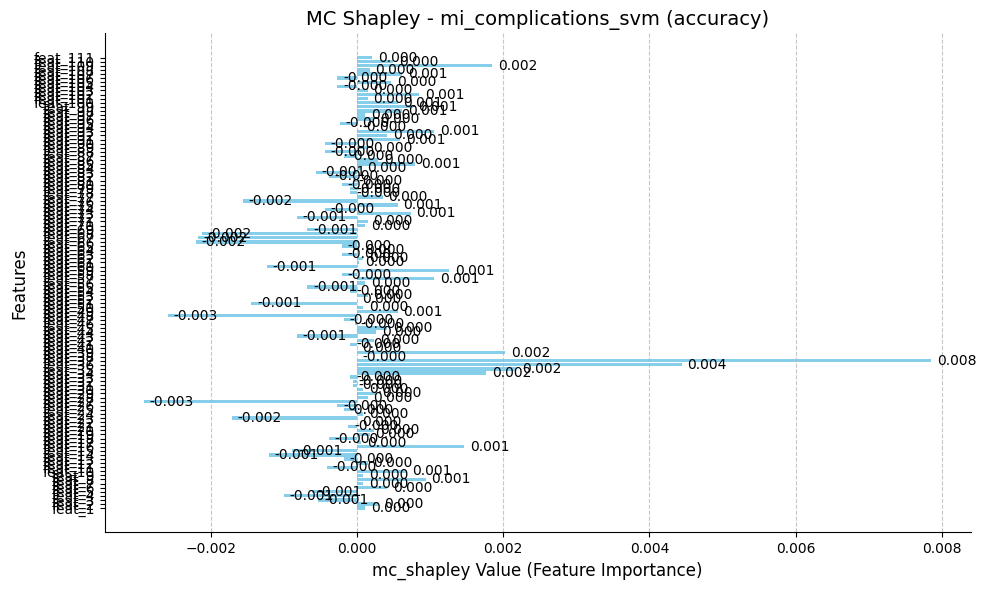

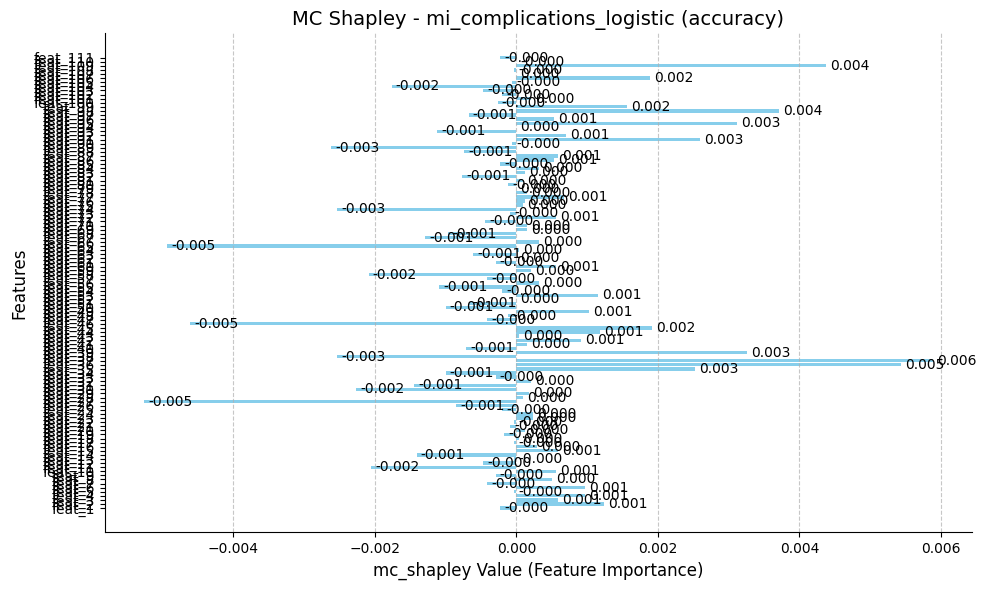

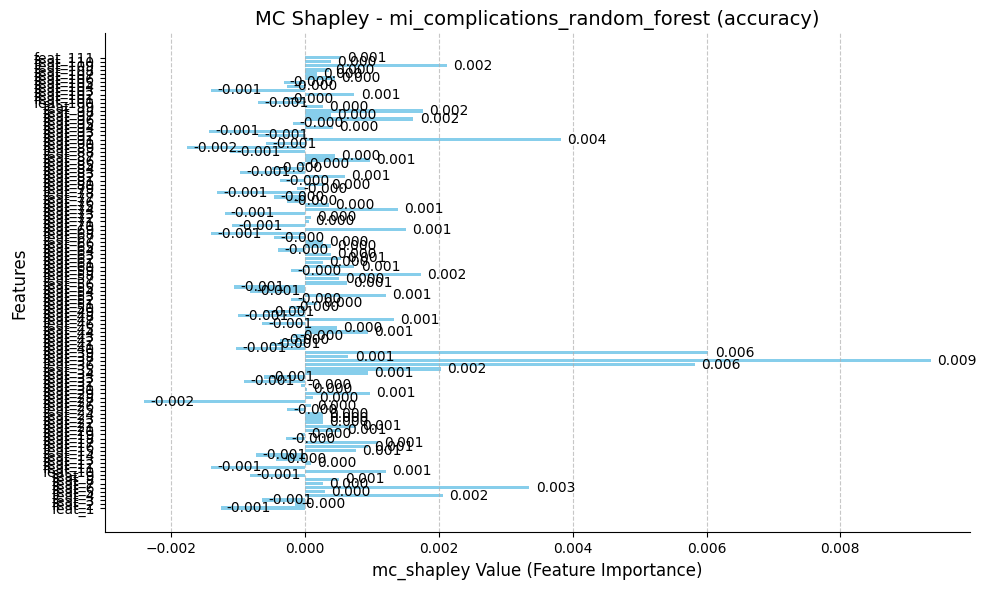

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config

DATASETS = ["mi_complications"]   #UCI datasets
MODEL_NAMES = ["svm", "logistic", "random_forest"]          # adjust names to match get_model()
SCORING = "accuracy"
N_MC_ITERATIONS = 100
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Dataset loaders for UCI Lung Cancer and MI Complications

def load_lung_cancer():
    """
    UCI Lung Cancer dataset:
    - File: lung-cancer.data
    - First column: class label (1,2,3)
    - Rest: features (some '?')
    """
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # target
    y = df.iloc[:, 0].astype(int).values

    # features
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    """
    UCI Myocardial Infarction Complications dataset:
    - File: MI.data
    - We'll treat LET_IS (col 123) as binary death outcome (dead vs alive).
    - Features: columns 1..111
    """
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # features: columns 1..111
    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    # LET_IS at column 123: 0 = alive, 1..7 = different death categories
    let_is = df.iloc[:, 123].astype(int).values

    if binary_let_is:
        y = (let_is != 0).astype(int)
    else:
        y = let_is  # multi-class (0..7)

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")


class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority-class baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")


# Main: do "all the things" for each dataset + model

def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "="*70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("="*70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            all_features_set = set(range(n_features))
            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            # 1. MC Shapley feature attributions (NO exact)
            logger.info("Computing Monte Carlo Shapley values...")
            shapley_result = montecarlo_shapley_value(
                utility,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals = shapley_result.values

            # Save per-feature values
            df_vals = pd.DataFrame({
                "method": "mc_shapley",
                "feature": feature_names,
                "value": shapley_vals
            })
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_mc_shapley.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved MC Shapley valuations to: {vals_csv_path}")

            # Optional: bar plot
            try:
                plot_single_valuation(
                    shapley_vals,
                    feature_names,
                    method_name="mc_shapley",
                    title=f"MC Shapley - {dataset_name}_{model_name} ({SCORING})",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_mc_shapley.png"
                )
            except Exception as e:
                logger.warning(f"  Could not plot MC Shapley for {dataset_name}, {model_name}: {e}")

            results = {"mc_shapley": shapley_vals}

            # 2. Global sensitivity (leave-one-out impact)
            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

            global_impacts = []
            for i in range(n_features):
                features_except_i = list(all_features_set - {i})
                v_N_minus_i = utility(features_except_i)
                impact = v_N - v_N_minus_i
                global_impacts.append(impact)
                logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

            global_impact_vector = np.array(global_impacts)

            sensitivity_results = []
            for method_name, attribution_values in results.items():
                if attribution_values is None:
                    logger.warning(f"  Skipping {method_name} (None values)")
                    continue

                corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)
                corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

                cos_sim = np.dot(attribution_values, global_impact_vector) / (
                    (np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector)) + 1e-10
                )

                sensitivity_results.append({
                    "method": method_name,
                    "sensitivity_spearman": corr_spearman,
                    "p_value_spearman": p_spearman,
                    "sensitivity_pearson": corr_pearson,
                    "p_value_pearson": p_pearson,
                    "cosine_similarity": cos_sim
                })

                logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, "
                            f"Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

            sensitivity_df = pd.DataFrame(sensitivity_results)
            logger.info("\nGLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
            logger.info(sensitivity_df.to_string(index=False))

            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_mc_shapley.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            # 3. Global robustness (noise stability)
            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(
                0,
                noise_level * X_train.std(axis=0),
                X_train.shape
            )
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Recompute MC Shapley on noisy data
            shapley_noisy_result = montecarlo_shapley_value(
                utility_noisy,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals_noisy = shapley_noisy_result.values

            noisy_results = {"mc_shapley": shapley_vals_noisy}

            robustness_results = []
            for method_name in results.keys():
                if method_name not in noisy_results:
                    logger.warning(f"  Skipping {method_name} (no noisy data)")
                    continue

                phi_original = results[method_name]
                phi_noisy = noisy_results[method_name]

                cos_sim = np.dot(phi_original, phi_noisy) / (
                    (np.linalg.norm(phi_original) * np.linalg.norm(phi_noisy)) + 1e-10
                )

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)

                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_results.append({
                    "method": method_name,
                    "cosine_similarity": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(f"  {method_name}: Cosine={cos_sim:.4f}, "
                            f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}")

            robustness_df = pd.DataFrame(robustness_results)
            logger.info("\n" + "="*70)
            logger.info("GLOBAL ROBUSTNESS (STABILITY) METRICS")
            logger.info("="*70)
            logger.info(robustness_df.to_string(index=False))

            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_mc_shapley.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            # 4. Combined faithfulness figure (3 panels)
            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            # Panel 1: sensitivity (Spearman)
            ax1 = axes[0]
            methods = sensitivity_df["method"]
            sens_scores = sensitivity_df["sensitivity_spearman"]
            colors = ['steelblue' if x > 0.5 else 'coral' for x in sens_scores]

            ax1.barh(methods, sens_scores, color=colors)
            ax1.set_xlabel("Spearman Correlation", fontsize=12)
            ax1.set_title("Global Sensitivity\n(Attribution ↔ Leave-One-Out Impact)",
                          fontsize=14, fontweight='bold')
            ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='No correlation')
            ax1.axvline(0.7, color='green', linestyle='--', linewidth=1,
                        alpha=0.5, label='Strong correlation')
            ax1.grid(axis='x', alpha=0.3)
            ax1.legend(fontsize=9)

            # Panel 2: sensitivity alignment (cosine)
            ax2 = axes[1]
            cos_scores = sensitivity_df["cosine_similarity"]
            colors2 = ['darkgreen' if x > 0.7 else 'orange' for x in cos_scores]

            ax2.barh(methods, cos_scores, color=colors2)
            ax2.set_xlabel("Cosine Similarity", fontsize=12)
            ax2.set_title("Attribution Alignment\n(Cosine Similarity)",
                          fontsize=14, fontweight='bold')
            ax2.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect alignment')
            ax2.grid(axis='x', alpha=0.3)
            ax2.legend(fontsize=9)

            # Panel 3: robustness (cosine original vs noisy)
            ax3 = axes[2]
            if len(robustness_df) > 0:
                rob_scores = robustness_df["cosine_similarity"]
                colors3 = ['purple' if x > 0.9 else 'salmon' for x in rob_scores]

                ax3.barh(robustness_df["method"], rob_scores, color=colors3)
                ax3.set_xlabel("Cosine Similarity (Original ↔ Noisy)", fontsize=12)
                ax3.set_title("Global Robustness\n(Stability Under Noise)",
                              fontsize=14, fontweight='bold')
                ax3.axvline(1.0, color='green', linestyle='--', linewidth=1,
                            label='Perfect stability')
                ax3.axvline(0.9, color='orange', linestyle='--', linewidth=1,
                            alpha=0.5, label='Good stability')
                ax3.grid(axis='x', alpha=0.3)
                ax3.legend(fontsize=9)
            else:
                ax3.text(0.5, 0.5, 'Robustness data not available',
                         ha='center', va='center', transform=ax3.transAxes)
                ax3.set_title("Global Robustness", fontsize=14, fontweight='bold')

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_mc_shapley.png"
            plt.savefig(fig_path, dpi=300, bbox_inches='tight')
            plt.close(fig)

            logger.info(f"\nAll faithfulness results saved to: {OUTPUT_DIR}")
            logger.info("="*70)


if __name__ == "__main__":
    main()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config

DATASETS = ["lung_cancer"]   #UCI datasets
MODEL_NAMES = ["svm", "logistic", "random_forest"]          # adjust names to match get_model()
SCORING = "accuracy"
N_MC_ITERATIONS = 1000
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Dataset loaders for UCI Lung Cancer and MI Complications

def load_lung_cancer():
    """
    UCI Lung Cancer dataset:
    - File: lung-cancer.data
    - First column: class label (1,2,3)
    - Rest: features (some '?')
    """
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # target
    y = df.iloc[:, 0].astype(int).values

    # features
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    """
    UCI Myocardial Infarction Complications dataset:
    - File: MI.data
    - We'll treat LET_IS (col 123) as binary death outcome (dead vs alive).
    - Features: columns 1..111
    """
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # features: columns 1..111
    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    # LET_IS at column 123: 0 = alive, 1..7 = different death categories
    let_is = df.iloc[:, 123].astype(int).values

    if binary_let_is:
        y = (let_is != 0).astype(int)
    else:
        y = let_is  # multi-class (0..7)

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")


class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority-class baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")


# Main: do "all the things" for each dataset + model

def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "="*70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("="*70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            all_features_set = set(range(n_features))
            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            # 1. MC Shapley feature attributions (NO exact)
            logger.info("Computing Monte Carlo Shapley values...")
            shapley_result = montecarlo_shapley_value(
                utility,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals = shapley_result.values

            # Save per-feature values
            df_vals = pd.DataFrame({
                "method": "mc_shapley",
                "feature": feature_names,
                "value": shapley_vals
            })
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_mc_shapley.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved MC Shapley valuations to: {vals_csv_path}")

            # Optional: bar plot
            try:
                plot_single_valuation(
                    shapley_vals,
                    feature_names,
                    method_name="mc_shapley",
                    title=f"MC Shapley - {dataset_name}_{model_name} ({SCORING})",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_mc_shapley.png"
                )
            except Exception as e:
                logger.warning(f"  Could not plot MC Shapley for {dataset_name}, {model_name}: {e}")

            results = {"mc_shapley": shapley_vals}

            # 2. Global sensitivity (leave-one-out impact)
            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

            global_impacts = []
            for i in range(n_features):
                features_except_i = list(all_features_set - {i})
                v_N_minus_i = utility(features_except_i)
                impact = v_N - v_N_minus_i
                global_impacts.append(impact)
                logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

            global_impact_vector = np.array(global_impacts)

            sensitivity_results = []
            for method_name, attribution_values in results.items():
                if attribution_values is None:
                    logger.warning(f"  Skipping {method_name} (None values)")
                    continue

                corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)
                corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

                cos_sim = np.dot(attribution_values, global_impact_vector) / (
                    (np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector)) + 1e-10
                )

                sensitivity_results.append({
                    "method": method_name,
                    "sensitivity_spearman": corr_spearman,
                    "p_value_spearman": p_spearman,
                    "sensitivity_pearson": corr_pearson,
                    "p_value_pearson": p_pearson,
                    "cosine_similarity": cos_sim
                })

                logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, "
                            f"Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

            sensitivity_df = pd.DataFrame(sensitivity_results)
            logger.info("\nGLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
            logger.info(sensitivity_df.to_string(index=False))

            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_mc_shapley.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            # 3. Global robustness (noise stability)
            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(
                0,
                noise_level * X_train.std(axis=0),
                X_train.shape
            )
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Recompute MC Shapley on noisy data
            shapley_noisy_result = montecarlo_shapley_value(
                utility_noisy,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals_noisy = shapley_noisy_result.values

            noisy_results = {"mc_shapley": shapley_vals_noisy}

            robustness_results = []
            for method_name in results.keys():
                if method_name not in noisy_results:
                    logger.warning(f"  Skipping {method_name} (no noisy data)")
                    continue

                phi_original = results[method_name]
                phi_noisy = noisy_results[method_name]

                cos_sim = np.dot(phi_original, phi_noisy) / (
                    (np.linalg.norm(phi_original) * np.linalg.norm(phi_noisy)) + 1e-10
                )

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)

                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_results.append({
                    "method": method_name,
                    "cosine_similarity": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(f"  {method_name}: Cosine={cos_sim:.4f}, "
                            f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}")

            robustness_df = pd.DataFrame(robustness_results)
            logger.info("\n" + "="*70)
            logger.info("GLOBAL ROBUSTNESS (STABILITY) METRICS")
            logger.info("="*70)
            logger.info(robustness_df.to_string(index=False))

            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_mc_shapley.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            # 4. Combined faithfulness figure (3 panels)
            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            # Panel 1: sensitivity (Spearman)
            ax1 = axes[0]
            methods = sensitivity_df["method"]
            sens_scores = sensitivity_df["sensitivity_spearman"]
            colors = ['steelblue' if x > 0.5 else 'coral' for x in sens_scores]

            ax1.barh(methods, sens_scores, color=colors)
            ax1.set_xlabel("Spearman Correlation", fontsize=12)
            ax1.set_title("Global Sensitivity\n(Attribution ↔ Leave-One-Out Impact)",
                          fontsize=14, fontweight='bold')
            ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='No correlation')
            ax1.axvline(0.7, color='green', linestyle='--', linewidth=1,
                        alpha=0.5, label='Strong correlation')
            ax1.grid(axis='x', alpha=0.3)
            ax1.legend(fontsize=9)

            # Panel 2: sensitivity alignment (cosine)
            ax2 = axes[1]
            cos_scores = sensitivity_df["cosine_similarity"]
            colors2 = ['darkgreen' if x > 0.7 else 'orange' for x in cos_scores]

            ax2.barh(methods, cos_scores, color=colors2)
            ax2.set_xlabel("Cosine Similarity", fontsize=12)
            ax2.set_title("Attribution Alignment\n(Cosine Similarity)",
                          fontsize=14, fontweight='bold')
            ax2.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect alignment')
            ax2.grid(axis='x', alpha=0.3)
            ax2.legend(fontsize=9)

            # Panel 3: robustness (cosine original vs noisy)
            ax3 = axes[2]
            if len(robustness_df) > 0:
                rob_scores = robustness_df["cosine_similarity"]
                colors3 = ['purple' if x > 0.9 else 'salmon' for x in rob_scores]

                ax3.barh(robustness_df["method"], rob_scores, color=colors3)
                ax3.set_xlabel("Cosine Similarity (Original ↔ Noisy)", fontsize=12)
                ax3.set_title("Global Robustness\n(Stability Under Noise)",
                              fontsize=14, fontweight='bold')
                ax3.axvline(1.0, color='green', linestyle='--', linewidth=1,
                            label='Perfect stability')
                ax3.axvline(0.9, color='orange', linestyle='--', linewidth=1,
                            alpha=0.5, label='Good stability')
                ax3.grid(axis='x', alpha=0.3)
                ax3.legend(fontsize=9)
            else:
                ax3.text(0.5, 0.5, 'Robustness data not available',
                         ha='center', va='center', transform=ax3.transAxes)
                ax3.set_title("Global Robustness", fontsize=14, fontweight='bold')

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_mc_shapley.png"
            plt.savefig(fig_path, dpi=300, bbox_inches='tight')
            plt.close(fig)

            logger.info(f"\nAll faithfulness results saved to: {OUTPUT_DIR}")
            logger.info("="*70)


if __name__ == "__main__":
    main()